In [11]:
import pandas as pd

df = pd.read_csv(
    "../data/processed/telecom_customers_clean.csv"
)

X = df.drop(columns=["customerID", "Churn"])

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [13]:
import mlflow
import mlflow.sklearn

import pandas as pd

In [14]:
mlflow.set_experiment(
    "customer_churn_classification"
)

<Experiment: artifact_location='/home/younessaj/PythonProjects/customer-churn-ml/notebooks/mlruns/1', creation_time=1791736766347, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791736766347, lifecycle_stage='active', name='customer_churn_classification', tags={}, trace_location=None, workspace='default'>

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "NumServices"
]

categorical_features = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [16]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression

smote_logistic_pipeline = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", LogisticRegression(
            max_iter=1000,
            C=1,
            solver="lbfgs"
        ))
    ]
)

In [17]:
smote_logistic_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](20,)","['gender','SeniorCitizen','Partner',...,'MonthlyCharges','TotalCharges', 'NumServices']"
n_features_in_,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [18]:
y_pred = smote_logistic_pipeline.predict(X_test)

y_prob = smote_logistic_pipeline.predict_proba(X_test)[:, 1]

In [19]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

In [20]:
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("ROC-AUC:", roc_auc)

Precision: 0.5076660988074957
Recall: 0.7967914438502673
F1-score: 0.6201873048907388
ROC-AUC: 0.8399390322663981


In [27]:
with mlflow.start_run(run_name="Logistic_SMOTE"):

    # Model hyperparameters
    mlflow.log_param("model", "LogisticRegression")
    mlflow.log_param("C", 1)
    mlflow.log_param("solver", "lbfgs")
    mlflow.log_param("max_iter", 1000)

    # SMOTE
    mlflow.log_param("smote", True)
    mlflow.log_param("smote_random_state", 42)

    # Preprocessing
    mlflow.log_param("scaler", "StandardScaler")
    mlflow.log_param("encoder", "OneHotEncoder")
    mlflow.log_param("handle_unknown", "ignore")

    # Metrics
    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1_score", f1)
    mlflow.log_metric("roc_auc", roc_auc)

    # Preprocessing artifact
    preprocessing_info = {
        "numeric_features": numeric_features,
        "categorical_features": categorical_features,
        "scaler": "StandardScaler",
        "encoder": "OneHotEncoder",
        "handle_unknown": "ignore",
        "smote": "SMOTE(random_state=42)"
    }

    mlflow.log_dict(
        preprocessing_info,
        "preprocessing/preprocessing_info.json"
    )

    # Confusion matrix
    mlflow.log_artifact(
        "confusion_matrix.png",
        artifact_path="plots"
    )

    # Trained model
    mlflow.sklearn.log_model(
        smote_logistic_pipeline,
        name="model",
        skops_trusted_types=[
            "imblearn.over_sampling._smote.base.SMOTE",
            "imblearn.pipeline.Pipeline"
        ]
    )

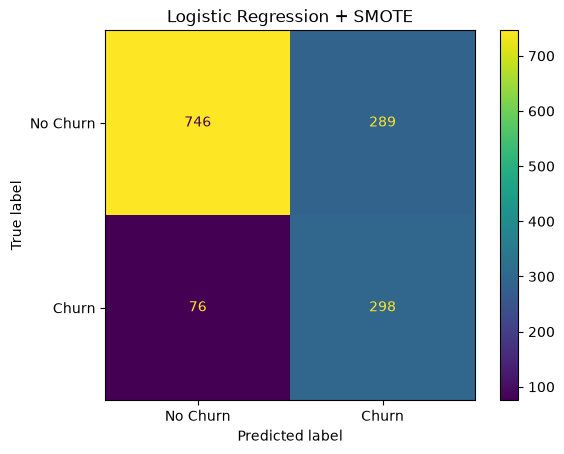

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()

plt.title("Logistic Regression + SMOTE")
plt.savefig("confusion_matrix.png", bbox_inches="tight")
plt.show()

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier

gradient_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingClassifier(
                n_estimators=100,
                learning_rate=0.1,
                max_depth=4,
                random_state=42
            )
        )
    ]
)

gradient_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['gender','SeniorCitizen','Partner',...,'MonthlyCharges','TotalCharges', 'NumServices']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

In [30]:
gb_pred = gradient_pipeline.predict(X_test)

gb_prob = gradient_pipeline.predict_proba(X_test)[:, 1]

In [31]:
gb_precision = precision_score(y_test, gb_pred)
gb_recall = recall_score(y_test, gb_pred)
gb_f1 = f1_score(y_test, gb_pred)
gb_roc_auc = roc_auc_score(y_test, gb_prob)

print("Precision:", gb_precision)
print("Recall:", gb_recall)
print("F1-score:", gb_f1)
print("ROC-AUC:", gb_roc_auc)

Precision: 0.65
Recall: 0.5213903743315508
F1-score: 0.5786350148367952
ROC-AUC: 0.8420677361853832


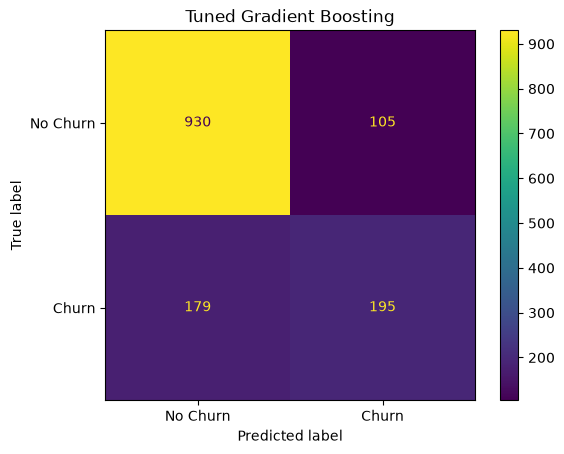

In [32]:
gb_cm = confusion_matrix(y_test, gb_pred)

gb_disp = ConfusionMatrixDisplay(
    confusion_matrix=gb_cm,
    display_labels=["No Churn", "Churn"]
)

gb_disp.plot()

plt.title("Tuned Gradient Boosting")
plt.savefig(
    "confusion_matrix_gradient_boosting.png",
    bbox_inches="tight"
)

plt.show()

In [36]:
with mlflow.start_run(run_name="Tuned_Gradient_Boosting"):

    # Parameters
    mlflow.log_param("model", "GradientBoostingClassifier")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("learning_rate", 0.1)
    mlflow.log_param("max_depth", 4)
    mlflow.log_param("random_state", 42)

    # Preprocessing
    mlflow.log_param("scaler", "StandardScaler")
    mlflow.log_param("encoder", "OneHotEncoder")
    mlflow.log_param("handle_unknown", "ignore")
    mlflow.log_param("smote", False)

    # Metrics
    mlflow.log_metric("precision", gb_precision)
    mlflow.log_metric("recall", gb_recall)
    mlflow.log_metric("f1_score", gb_f1)
    mlflow.log_metric("roc_auc", gb_roc_auc)

    # Preprocessing artifact
    preprocessing_info_gb = {
        "numeric_features": numeric_features,
        "categorical_features": categorical_features,
        "scaler": "StandardScaler",
        "encoder": "OneHotEncoder",
        "handle_unknown": "ignore",
        "smote": False
    }

    mlflow.log_dict(
        preprocessing_info_gb,
        "preprocessing/preprocessing_info.json"
    )

    # Confusion matrix
    mlflow.log_artifact(
        "confusion_matrix_gradient_boosting.png",
        artifact_path="plots"
    )

    # Save model
    mlflow.sklearn.log_model(
        gradient_pipeline,
        name="model",
        skops_trusted_types=[
            "sklearn.tree._tree.Tree"
        ]
    )